In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [3]:
df = pd.read_csv("netflix_customer_churn.csv")
df.head(5)

,customer_id,age,gender,subscription_type,watch_hours,last_login_days,region,device,monthly_fee,churned,payment_method,number_of_profiles,avg_watch_time_per_day,favorite_genre
0,a9b75100-82a8-427a-a208-72f24052884a,51,Other,Basic,14.73,29,Africa,TV,8.99,1,Gift Card,1,0.49,Action
1,49a5dfd9-7e69-4022-a6ad-0a1b9767fb5b,47,Other,Standard,0.70,19,Europe,Mobile,13.99,1,Gift Card,5,0.03,Sci-Fi
2,4d71f6ce-fca9-4ff7-8afa-197ac24de14b,27,Female,Standard,16.32,10,Asia,TV,13.99,0,Crypto,2,1.48,Drama
3,d3c72c38-631b-4f9e-8a0e-de103cad1a7d,53,Other,Premium,4.51,12,Oceania,TV,17.99,1,Crypto,2,0.35,Horror
4,4e265c34-103a-4dbb-9553-76c9aa47e946,56,Other,Standard,1.89,13,Africa,Mobile,13.99,1,Crypto,2,0.13,Action


In [4]:
df.isnull().sum()

,0
customer_id,0
age,0
gender,0
subscription_type,0
watch_hours,0
last_login_days,0
region,0
device,0
monthly_fee,0
churned,0


In [5]:
print("Dataset Shape : ", df.shape)

Dataset Shape :  (5000, 14)


In [6]:
#Overall Churn Rate
churn_rate = df['churned'].mean() * 100
print("Churn Rate : ", churn_rate)

Churn Rate :  50.3


In [7]:
#Churn Rate by Subscribtion type

Summary = df.groupby('subscription_type').agg(
    monthly_fee = ('monthly_fee', 'mean'),
    churned_rate = ('churned', lambda x: x.mean() * 100),
    n_customer = ('churned', 'size')

)

print(Summary)

                   monthly_fee  churned_rate  n_customer
subscription_type                                       
Basic                     8.99     61.830223        1661
Premium                  17.99     43.709392        1693
Standard                 13.99     45.443499        1646


In [8]:
#churn by inactivity brackets
bins = [0, 10, 20, 30, 40, 50, 60]
labels = ['0-10d', '11-20d', '21-30d', '31-40d', '41-50d', '51-60d']
df['inactivity_group'] = pd.cut(df['last_login_days'], bins=bins, labels=labels, include_lowest=True)
inactivity_churn = df.groupby('inactivity_group', observed=False)['churned'].mean() * 100
print("Churn By Inactivity Cohort : ", inactivity_churn)

Churn By Inactivity Cohort :  inactivity_group
0-10d     16.979052
11-20d    26.709677
21-30d    35.335689
31-40d    72.506083
41-50d    78.054567
51-60d    74.626866
Name: churned, dtype: float64


In [9]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['churned', 'customer_id', 'inactivity_group', 'monthly_fee'])
y = df['churned']

X = pd.get_dummies(X, drop_first=True)

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42, stratify=y)

print(X_train.shape)
print(X_test.shape)




(4000, 28)
(1000, 28)


In [10]:
# Klasifikasi : Baseline vs Shooting

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score, f1_score, precision_score, recall_score
from xgboost import XGBClassifier   # pip install xgboost (kalau belum ada)

models = {
    "Logistic Regression" : make_pipeline(StandardScaler(), LogisticRegression(max_iter=1000)),
    "XGBoost" : XGBClassifier(n_estimators=300, learning_rate = 0.05, max_depth = 4 , random_state = 42,
                              eval_metric = "logloss"),
}

hasil = []

for nama, model in models.items():  # Ulangi untuk Setiap model di kamus
  model.fit(X_train, y_train) # Latih model dengan data latih
  proba = model.predict_proba(X_test)[:, 1] #probabilitas churn(kolom ke 2 = kelas 1) untuk dat uji
  pred = (proba >= 0.5 ).astype(int) # ubah probabilitas jadi label: >= 0,5 dianggap churn (1)
  hasil.append({
      "model" : nama, # nama model
      'roc_auc' : roc_auc_score(y_test, proba),  # kemampuan membedakan churn vs tidak, dari semua threshold
      'precision' : precision_score(y_test, pred), # dari yang diprediksi churn, berapa yang benar-benar churn
      'recall' : recall_score(y_test, pred), # dari yang benar-benar churn, berapa yang berhasil terdeteksi
      'f1' : f1_score(y_test, pred), # rata-rata harmonik precision dan recall
  })

print(pd.DataFrame(hasil).round(3)) # tampilkan tabel perbandingan, dibulatkan 3 desimal

                 model  roc_auc  precision  recall     f1
0  Logistic Regression    0.966      0.875   0.905  0.890
1              XGBoost    1.000      0.996   0.988  0.992


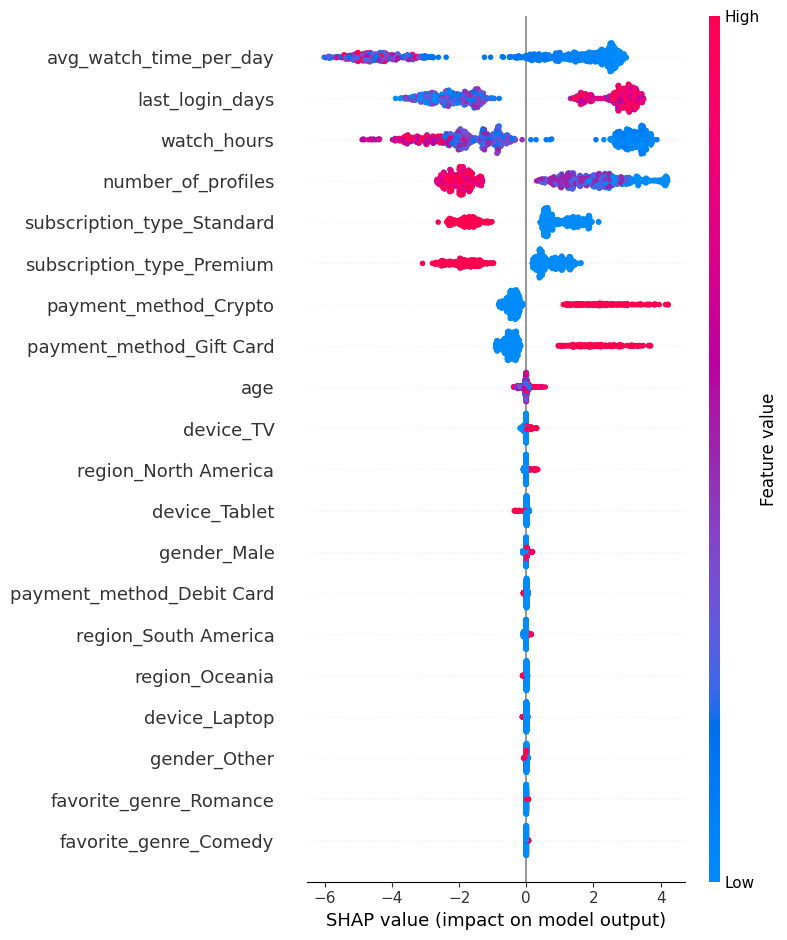

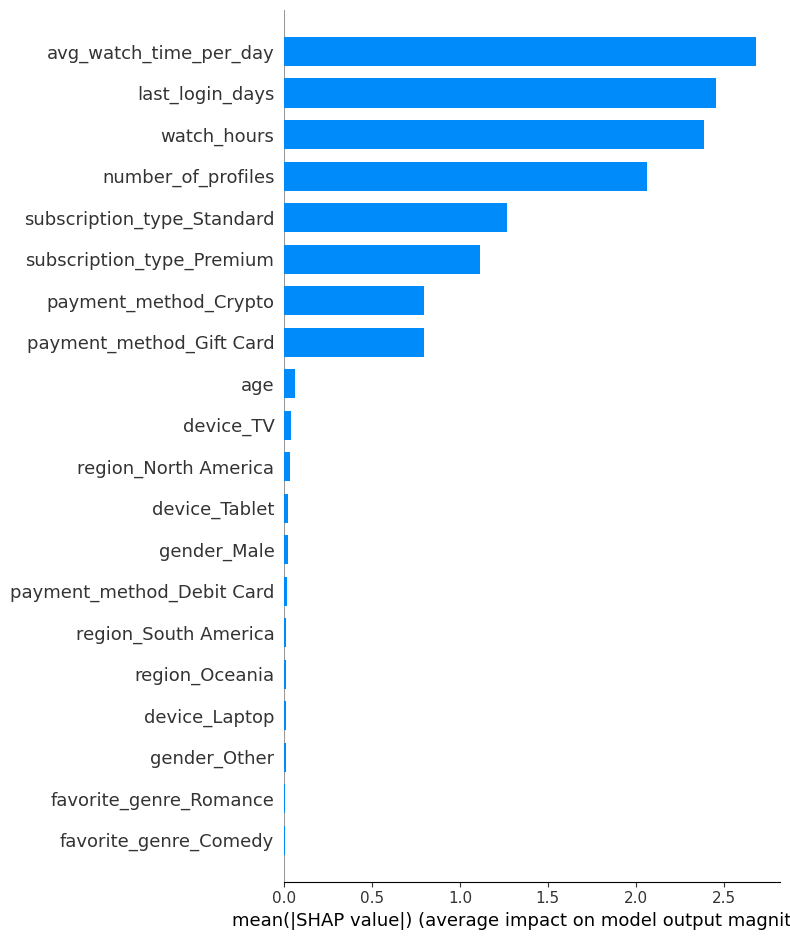

In [11]:
# SHAP: faktor pendorong churn
import shap

model = models['XGBoost'] # ambil model XGBoost yang sudah dilatih
explainer = shap.TreeExplainer(model) # pembuat penjelasan khusus model berbasis pohon
shap_values = explainer.shap_values(X_test) # hitung kontribusi tiap fitur untuk tiap pelanggan uji

shap.summary_plot(shap_values, X_test) # plot sebaran: tiap titik = 1 pelanggan; kanan = dorong churn
shap.summary_plot(shap_values, X_test, plot_type="bar") # plot batang: peringkat fitur berdasarkan pengaruh rata-rata

In [14]:
#Segmentasi Dengan K-means
from sklearn.cluster import KMeans  # algoritma pengelompokan berbasis jarak ke pusat kelompok
from sklearn.metrics import silhouette_score   # ukuran kualitas cluster (makin dekat 1 makin baik)

fitur_seg = [        # fitur perilaku yang dipakai untuk mengelompokkan
    "watch_hours",
    "avg_watch_time_per_day",
    "number_of_profiles",
    "last_login_days"
]

df_seg = df[df["avg_watch_time_per_day"] <= 24]   # buang baris mustahil (>24 jam/hari) agar cluster tidak terdistorsi
Xs = StandardScaler().fit_transform(df_seg[fitur_seg])  # normalisasi fitur

for k in range(2, 7):    # coba jumlah cluster dari 2 sampai 6
    labels = KMeans(      # buat model K-Means dengan k cluster
      n_clusters = k,   # jumlah cluster yang dicoba
      random_state = 42,     # supaya hasil bisa diulang
      n_init = 10  #ulangi Inisialisasi Sebanyak 10 kali dan ambil yang terbaik
    ).fit_predict(Xs)  # latih dan langsung beri label cluster tiap pelanggan
    print(k, round(silhouette_score(Xs, labels), 3))  # tampilkan nilai Silhouette untuk tiap k


km = KMeans(n_clusters = 4 , random_state =  42, n_init = 10) # pakai k pilihanmu (ganti 4 sesuai skor terbaik di atas)
df_seg = df_seg.copy()  # salin agar tidak muncul peringatan saat menambah kolom
df_seg['segment'] = km.fit_predict(Xs) # tambahkan kolom segmentasi ke data

print(
    df_seg.groupby('segment')[fitur_seg + ['churned']].mean().round(2)  # rata-rata fitur dan churn per segmen
)


2 0.417
3 0.27
4 0.285
5 0.294
6 0.296
         watch_hours  avg_watch_time_per_day  ...  last_login_days  churned
segment                                       ...                          
0               8.17                    0.53  ...            27.37     0.61
1               7.54                    0.35  ...            33.75     0.57
2              23.88                    9.36  ...             1.92     0.00
3              35.09                    1.44  ...            33.40     0.03

[4 rows x 5 columns]


In [15]:
#Simpan File untuk dijadikan Dashboard Streamlit
df_seg.to_csv("data_bersih.csv", index=False)         # simpan data (termasuk kolom segment) untuk dipakai dashboard